# FeatureRater: ERM-embedding t-SNE colored by rater weights

**Run in Google Colab using Runtime → Run all after checking cell 2.** A GPU is optional.
This notebook loads your frozen Waterbirds ERM embedding cache and frozen rater, without
training a classifier or loading images. It reproduces the two-panel structure of your
reference: **left = class/background groups; right = learned rater weights**, using exactly
the same coordinates and sample order. Yellow means **higher weight**, not uncertainty.

Defaults are copied from `Frozen_Rater_Final_Classifier_MultiSeed_MultiSelection (1).ipynb`:
small/medium rater auto-detection; ERM fingerprint `1055b1e8de29`; final-classifier training
split `val_subset1`, `split_val=0.6`, split seed 0; all-sample rating with global normalization,
sigmoid, temperature 1, scale 1. **Check that the checkpoint in cell 2 is the rater you want.**

On the test set these are the weights the frozen scoring rule **would assign**. Test data
are not used to fit the rater or normalization. To show weights on the final-classifier
training set instead, set `PLOT_SPLIT = "val_subset1"`.

**Needed on Drive:** `final_rater.pt`, the chosen embedding split, and the normalization
reference split (or `val.pt`, from which the same validation subsets can be derived in memory).
No final-classifier checkpoint, repository clone, or raw images are needed for the default.


In [52]:
# 1. Mount Drive and import dependencies.
MOUNT_DRIVE = True  # False for local Jupyter; update the paths in cell 2.
if MOUNT_DRIVE:
    try:
        from google.colab import drive
    except ImportError:
        print("Not running in Colab: using local filesystem paths.")
    else:
        drive.mount("/content/drive")

import importlib.util
import subprocess
import sys

# Install only missing libraries; keep an existing Colab PyTorch installation.
packages = {"torch": "torch", "numpy": "numpy", "pandas": "pandas",
            "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
missing = [pkg for mod, pkg in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import inspect
import json
import platform
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import Normalize
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import sklearn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
print("torch:", torch.__version__, "| scikit-learn:", sklearn.__version__)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu
torch: 2.11.0+cpu | scikit-learn: 1.6.1


In [53]:
# 2. CONFIGURATION — this is the main cell to edit.
# Shared project folder on Drive. Renamed to "FeatureRater" (Nov 2026); a Drive shortcut
# may still carry the old name, so both are accepted (the folder must contain archives/).
DRIVE_ROOT_NAMES = ("FeatureRater", "evidential_alignment_colab")
DRIVE_ROOT = next(
    (Path("/content/drive/MyDrive") / name for name in DRIVE_ROOT_NAMES
     if (Path("/content/drive/MyDrive") / name / "archives").exists()),
    Path("/content/drive/MyDrive") / DRIVE_ROOT_NAMES[-1],
)
print("Project folder on Drive:", DRIVE_ROOT)

# Drive layout (Nov 2026): waterbirds/<ERM_ID>/ holds the ERM checkpoint, its embeddings,
# raters/<run>/classifiers/, controls/, baselines/ and analysis/. Every path below falls
# back to the pre-November location, so this works before and after the reorganization.
ERM_ID = "erm-r50-e100-s0"
ERM_DIR = DRIVE_ROOT / "waterbirds" / ERM_ID
ERM_STABLE_NAME = "waterbirds_erm_resnet50_imagenet_100ep_best_val_acc.pt"
ERM_RUN_NAME = "erm_waterbirds_resnet50_train_128B_100E_seed0_pretrained"
CACHE_SUBDIR = "waterbirds/resnet50_waterbirds_erm_1055b1e8de29/resolution_224"

def first_existing(*paths):
    """First path that exists; the first one if none does."""
    for path in paths:
        if Path(path).exists():
            return Path(path)
    return Path(paths[0])

RATER_RUN = "ea_gated_full_epoch_on_all_20261005_081758"
RATER_CHECKPOINT = first_existing(
    ERM_DIR / "raters" / RATER_RUN / "final_rater.pt",
    DRIVE_ROOT / "waterbirds_raters/rater_meta_only_runs" / RATER_RUN / "final_rater.pt",
)
EMBEDDING_CACHE_ROOT = first_existing(
    ERM_DIR / "embeddings" / CACHE_SUBDIR,
    DRIVE_ROOT / "embeddings_waterbirds_erm" / CACHE_SUBDIR,
)
EXPECTED_ERM_FINGERPRINT = "1055b1e8de29"

# Optional: read settings from a *seed folder's* config.json saved by your training
# notebook. This imports paths, split settings and weight settings, and lets us
# check recomputed normalization against the exact recorded training values.
# Example: DRIVE_ROOT / "frozen_rater_final_multiseed_multiselection/.../seed_69/config.json"
FINAL_RUN_CONFIG = None

PLOT_SPLIT = "test"  # "test", "val_subset1", "val_subset2", "val", "train_no_aug"
NORMALIZATION_REFERENCE_SPLIT = "val_subset1"  # final-classifier training split!
SPLIT_VAL = 0.6
DATA_SPLIT_SEED = 0
NORMALIZATION_MODE = "global"  # "global" or "none" for static per-example weights
WEIGHT_TRANSFORM = "sigmoid"
TEMPERATURE = 1.0
WEIGHT_SCALE = 1.0
RATING_MODE = "all"
COLOR_VALUE = "rater_weight"  # "rater_weight" or "raw_score"

# Default: plot every test point, preserving the split's actual group proportions.
# For a smaller random plot choose MAX_POINTS=2500, SAMPLING="random".
# A balanced diagnostic view deliberately changes the plotted group proportions.
MAX_POINTS = 4000
SAMPLING = "balanced_groups"  # "all", "random", "balanced_groups"
SAMPLE_SEED = 0
TSNE_SEED = 0
PCA_COMPONENTS = 50  # None disables PCA; no whitening or coordinate-wise scaling.
L2_NORMALIZE_FOR_TSNE = False  # affects only the plot, NEVER the rater inputs
TSNE_PERPLEXITY = 30.0
TSNE_ITERATIONS = 3000
INFERENCE_BATCH_SIZE = 512

CLASS_NAMES = {0: "Landbird", 1: "Waterbird"}
BACKGROUND_NAMES = {0: "land", 1: "water"}
POINT_SIZE = 9
POINT_ALPHA = 0.9
SHOW_TICKS = True
# For sigmoid weights use their actual mathematical range; no min-max recoloring.
# Set a narrower (low, high) range only deliberately; a colorbar extension shows clipping.
COLOR_LIMITS = None
SAVE_FORMATS = ("png", "pdf", "svg")
PNG_DPI = 600
OUTPUT_ROOT = ERM_DIR / "analysis" / "tsne" if ERM_DIR.exists() else DRIVE_ROOT / "feature_rater_tsne"

run_config = {}
if FINAL_RUN_CONFIG is not None:
    config_path = Path(FINAL_RUN_CONFIG)
    run_config = json.loads(config_path.read_text())
    for field, key in {
        "RATER_CHECKPOINT": "rater_checkpoint",
        "EMBEDDING_CACHE_ROOT": "embedding_cache_root",
        "EXPECTED_ERM_FINGERPRINT": "expected_erm_fingerprint",
        "SPLIT_VAL": "split_val", "NORMALIZATION_MODE": "normalization_mode",
        "WEIGHT_TRANSFORM": "weight_transform", "TEMPERATURE": "temperature",
        "WEIGHT_SCALE": "weight_scale", "RATING_MODE": "rating_mode",
    }.items():
        if key in run_config:
            globals()[field] = run_config[key]
    DATA_SPLIT_SEED = int(run_config.get("split_seed", run_config.get("data_split_seed", DATA_SPLIT_SEED)))
    if run_config.get("vary_data_split_with_seed") and "split_seed" not in run_config:
        raise ValueError("Use a seed folder's config.json to identify its varying data split.")
    NORMALIZATION_REFERENCE_SPLIT = run_config.get("split_names", {}).get("train", "val_subset1")

RATER_CHECKPOINT = Path(RATER_CHECKPOINT)
EMBEDDING_CACHE_ROOT = Path(EMBEDDING_CACHE_ROOT)
assert RATER_CHECKPOINT.is_file(), f"Set RATER_CHECKPOINT to an existing checkpoint: {RATER_CHECKPOINT}"
assert EMBEDDING_CACHE_ROOT.is_dir(), f"Missing embedding cache: {EMBEDDING_CACHE_ROOT}"
assert COLOR_VALUE in {"rater_weight", "raw_score"}
assert SAMPLING in {"all", "random", "balanced_groups"}
assert 0 < SPLIT_VAL < 1 and INFERENCE_BATCH_SIZE > 0
assert 0 < TSNE_PERPLEXITY and TSNE_ITERATIONS > 250
assert MAX_POINTS is None or (isinstance(MAX_POINTS, int) and MAX_POINTS >= 4)
assert SAMPLING != "all" or MAX_POINTS is None, "Set SAMPLING='random' to limit MAX_POINTS."
if COLOR_VALUE == "rater_weight":
    if RATING_MODE != "all" or NORMALIZATION_MODE not in {"global", "none"} or WEIGHT_TRANSFORM != "sigmoid":
        raise ValueError(
            "Static weights here require all-sample rating, global/none normalization, and sigmoid. "
            "Batch normalization/softmax depend on batch composition; misclassified mode also "
            "depends on the current classifier. Choose COLOR_VALUE='raw_score' to visualize "
            "the frozen rater's batch-independent preference in those configurations."
        )
    assert TEMPERATURE > 0 and WEIGHT_SCALE > 0

random.seed(TSNE_SEED)
np.random.seed(TSNE_SEED)
torch.manual_seed(TSNE_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TSNE_SEED)

print("Rater:", RATER_CHECKPOINT)
print("Plot split:", PLOT_SPLIT, "| normalization reference:", NORMALIZATION_REFERENCE_SPLIT)
print("Color:", COLOR_VALUE, "|", NORMALIZATION_MODE, WEIGHT_TRANSFORM)


Rater: /content/drive/MyDrive/evidential_alignment_colab/waterbirds_raters/rater_meta_only_runs/ea_gated_full_epoch_on_all_20261005_081758/final_rater.pt
Plot split: test | normalization reference: val_subset1
Color: rater_weight | global sigmoid


### What the right panel measures

For the supplied default configuration, with frozen rater output $s_i=r(z_i)$,

$$w_i=\alpha\,\sigma\left(\frac{(s_i-\mu_{\rm train})/(\sigma_{\rm train}+10^{-6})}{T}\right).$$

Here $\mu_{\rm train}$ and $\sigma_{\rm train}$ come from **all final-classifier training
examples**, before any plotting subsample; the standard deviation uses `unbiased=False`,
exactly as in your notebook. `alpha=WEIGHT_SCALE`, `T=TEMPERATURE`. These settings describe
**final-classifier use** of the rater and need not match the meta-training settings saved
inside the rater checkpoint. Embeddings go into the rater unchanged.

The static weight view supports your supplied `all + global + sigmoid` configuration and
`all + none + sigmoid`. With batch normalization, softmax, or correctness gating, weights
are contextual; select `COLOR_VALUE="raw_score"` to plot rater outputs without claiming
they are the effective training coefficients. No group labels are given to the rater.


In [54]:
# 3. Load cached embeddings; derive missing validation subsets IN MEMORY.
# torch.load(..., weights_only=False) matches the supplied notebook. Use trusted files.
def load_pt(path):
    return torch.load(Path(path), map_location="cpu", weights_only=False)

def fingerprint(metadata):
    return metadata.get("erm_checkpoint_fingerprint") or metadata.get("erm_fingerprint")

def check_fingerprint(metadata, context):
    found = fingerprint(metadata)
    if found is not None and str(found) != str(EXPECTED_ERM_FINGERPRINT):
        raise RuntimeError(f"{context}: ERM fingerprint {found} != {EXPECTED_ERM_FINGERPRINT}")
    if found is None:
        warnings.warn(f"{context}: no ERM fingerprint recorded; compatibility cannot be verified.")
    return found

loaded_splits = {}
cache_provenance = {}
def load_split(name):
    if name in loaded_splits:
        return loaded_splits[name]
    if name in {"train_no_aug", "val", "test"}:
        path = EMBEDDING_CACHE_ROOT / f"{name}.pt"
    elif name in {"val_subset1", "val_subset2"}:
        token = str(SPLIT_VAL).replace(".", "p")
        path = EMBEDDING_CACHE_ROOT / f"{name}_splittrain_1p0_splitval_{token}_seed_{DATA_SPLIT_SEED}.pt"
    else:
        raise ValueError(f"Unknown split: {name}")

    derived = False
    if path.is_file():
        payload = load_pt(path)
    elif name in {"val_subset1", "val_subset2"}:
        full = load_split("val")
        order = np.arange(len(full["labels"]))
        np.random.RandomState(DATA_SPLIT_SEED).shuffle(order)
        cut = int(len(order) * SPLIT_VAL)
        selected = order[:cut] if name == "val_subset1" else order[cut:]
        idx = torch.as_tensor(selected, dtype=torch.long)
        payload = {key: full[key][idx].clone() for key in ["embeddings", "labels", "groups", "attrs"]}
        # Matches ensure_val_subsets in the source notebook: row indices in full val.
        payload["source_indices"] = idx
        payload["cache_metadata"] = dict(full.get("cache_metadata", {}))
        payload["cache_metadata"].update(split=name, derived_from_full_val_cache=True)
        path = EMBEDDING_CACHE_ROOT / "val.pt"
        derived = True
        print(f"Derived {name} in memory, using exactly the original RandomState split.")
    else:
        raise FileNotFoundError(f"Missing {path}. Reuse the ERM embedding caches from your training notebook.")

    if not isinstance(payload, dict):
        raise TypeError(f"{name}: expected a dictionary cache.")
    data = {}
    for key in ["embeddings", "labels", "groups", "attrs"]:
        if key not in payload:
            raise KeyError(f"{name}: missing key {key!r}")
        value = torch.as_tensor(payload[key]).detach().cpu()
        if not torch.isfinite(value).all():
            raise ValueError(f"{name}: nonfinite {key}")
        if key != "embeddings" and (value.ndim != 1 or not torch.equal(value, value.long().to(value.dtype))):
            raise ValueError(f"{name}: {key} must be a 1D integer array")
        data[key] = value.float() if key == "embeddings" else value.long()
    n = len(data["labels"])
    if n < 2 or data["embeddings"].shape != (n, 2048):
        raise ValueError(f"{name}: expected nonempty (N, 2048) embeddings, got {tuple(data['embeddings'].shape)}")
    if any(len(data[key]) != n for key in ["groups", "attrs"]):
        raise ValueError(f"{name}: inconsistent row counts")
    source_indices = torch.as_tensor(payload.get("source_indices", torch.arange(n))).long().cpu()
    if source_indices.shape != (n,):
        raise ValueError(f"{name}: invalid source_indices shape")
    data["source_indices"] = source_indices
    data["cache_metadata"] = dict(payload.get("cache_metadata", {}))
    representation = data["cache_metadata"].get("representation_source")
    if representation and representation != "waterbirds_erm_checkpoint":
        raise RuntimeError(f"{name}: not a Waterbirds-ERM embedding cache: {representation}")
    check_fingerprint(data["cache_metadata"], name)
    loaded_splits[name] = data
    cache_provenance[name] = {
        "path": str(path), "derived_in_memory": derived, "n": n,
        "bytes": path.stat().st_size, "mtime_ns": path.stat().st_mtime_ns,
        "metadata": data["cache_metadata"],
    }
    return data

plot_data = load_split(PLOT_SPLIT)
print("Plot embeddings:", tuple(plot_data["embeddings"].shape))


Plot embeddings: (5794, 2048)


In [55]:
# 4. Exact rater architectures from the uploaded notebook.
class EmbeddingRaterSmall(nn.Module):
    def __init__(self, input_dim=2048):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
        )

    def forward(self, z):
        return self.net(z).squeeze(-1)


class EmbeddingRaterMedium(nn.Module):
    def __init__(self, input_dim=2048):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, 512),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(512, 256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, 64),
            nn.GELU(),
            nn.Linear(64, 1),
        )

    def forward(self, z):
        return self.net(z).squeeze(-1)

RATER_CKPT = load_pt(RATER_CHECKPOINT)
if not isinstance(RATER_CKPT, dict) or "rater_sd" not in RATER_CKPT:
    raise ValueError("Expected a final_rater.pt dictionary containing rater_sd.")
rater_state = RATER_CKPT["rater_sd"]
capacity = str(RATER_CKPT.get("rater_capacity", "")).lower()
if capacity not in {"small", "medium"}:
    first_weight = rater_state.get("net.1.weight")
    width = first_weight.shape[0] if first_weight is not None else None
    capacity = {256: "small", 512: "medium"}.get(width)
if capacity is None:
    raise RuntimeError("Could not infer small/medium rater architecture; provide its definition.")
rater = (EmbeddingRaterSmall(2048) if capacity == "small" else EmbeddingRaterMedium(2048))
rater.load_state_dict(rater_state, strict=True)
rater = rater.to(DEVICE).eval()
for parameter in rater.parameters():
    parameter.requires_grad_(False)
check_fingerprint(RATER_CKPT, "Rater checkpoint")
print("Loaded frozen", capacity, "rater.")

@torch.no_grad()
def score_embeddings(embeddings):
    result = torch.empty(len(embeddings), dtype=torch.float32)
    for start in range(0, len(embeddings), INFERENCE_BATCH_SIZE):
        end = min(start + INFERENCE_BATCH_SIZE, len(embeddings))
        result[start:end] = rater(embeddings[start:end].to(DEVICE)).detach().cpu()
    if not torch.isfinite(result).all():
        raise ValueError("The rater returned nonfinite scores.")
    return result


Loaded frozen medium rater.


In [56]:
# 5. Score all examples BEFORE sampling. Never normalize on plotted/test points.
raw_scores = score_embeddings(plot_data["embeddings"])
global_mean = global_std = None
if COLOR_VALUE == "rater_weight":
    if NORMALIZATION_MODE == "global":
        reference_data = load_split(NORMALIZATION_REFERENCE_SPLIT)
        reference_scores = (raw_scores if PLOT_SPLIT == NORMALIZATION_REFERENCE_SPLIT
                            else score_embeddings(reference_data["embeddings"]))
        global_mean = float(reference_scores.mean())
        global_std = float(reference_scores.std(unbiased=False))
        for key, actual in [("global_rater_mean", global_mean), ("global_rater_std", global_std)]:
            if key in run_config and not np.isclose(float(run_config[key]), actual, rtol=1e-4, atol=1e-5):
                raise RuntimeError(f"{key} disagrees with the saved run. Check rater, cache, and split seed.")
        if global_std < 1e-8:
            warnings.warn("Rater scores on the reference split are nearly constant.")
        normalized_scores = (raw_scores - global_mean) / (global_std + 1e-6)
        print(f"Training reference: n={len(reference_scores)}, mean={global_mean:.7g}, std={global_std:.7g}")
    else:
        normalized_scores = raw_scores.clone()
    rater_weights = WEIGHT_SCALE * torch.sigmoid(normalized_scores / TEMPERATURE)
    color_values = rater_weights.numpy()
    COLOR_LABEL = "Rater weight"
else:
    rater_weights = normalized_scores = None
    color_values = raw_scores.numpy()
    COLOR_LABEL = "Raw rater score"

# Always derive legend entries from (class, attribute), rather than assuming group=2*y+a.
all_points = pd.DataFrame({
    "split_row": np.arange(len(raw_scores)),
    "source_index": plot_data["source_indices"].numpy(),
    "class_id": plot_data["labels"].numpy(),
    "attribute_id": plot_data["attrs"].numpy(),
    "group_id": plot_data["groups"].numpy(),
    "raw_rater_score": raw_scores.numpy(),
    "color_value": color_values,
})
if rater_weights is not None:
    all_points["normalized_rater_score"] = normalized_scores.numpy()
    all_points["rater_weight"] = rater_weights.numpy()

pairs = sorted(set(zip(all_points.class_id, all_points.attribute_id)))
pair_to_index = {pair: i for i, pair in enumerate(pairs)}
all_points["pair_id"] = [pair_to_index[p] for p in zip(all_points.class_id, all_points.attribute_id)]
def pair_label(pair):
    y, a = pair
    return f"{CLASS_NAMES.get(y, f'Class {y}')}, {BACKGROUND_NAMES.get(a, str(a))} background"
pair_labels = {i: pair_label(p) for p, i in pair_to_index.items()}
all_points["group_label"] = all_points.pair_id.map(pair_labels)
mapping = all_points[["group_id", "pair_id"]].drop_duplicates()
if mapping.group_id.duplicated().any() or mapping.pair_id.duplicated().any():
    raise ValueError("Cached group IDs do not map one-to-one to (class, background). Check the cache.")

summary = all_points.groupby(["class_id", "attribute_id", "group_id", "group_label"], sort=True).agg(
    n=("color_value", "size"), mean=("color_value", "mean"),
    median=("color_value", "median"), std=("color_value", "std"),
    minimum=("color_value", "min"), maximum=("color_value", "max"),
).reset_index()
summary["sample_share"] = summary.n / len(all_points)
if rater_weights is not None:
    mass = all_points.groupby(["class_id", "attribute_id", "group_id", "group_label"], sort=True).rater_weight.sum().to_numpy()
    total_mass = float(mass.sum())
    summary["weight_mass_share"] = mass / total_mass if total_mass > 0 else np.nan
    summary["mass_share_over_sample_share"] = summary.weight_mass_share / summary.sample_share
summary["statistic"] = COLOR_LABEL
print("Full-split group statistics (not the plotting subsample):")
try:
    display(summary.round(5))
except NameError:
    print(summary.round(5).to_string(index=False))


Training reference: n=719, mean=-0.1710477, std=0.1816353
Full-split group statistics (not the plotting subsample):


,class_id,attribute_id,group_id,group_label,n,mean,median,std,minimum,maximum,sample_share,weight_mass_share,mass_share_over_sample_share,statistic
0,0,0,0,"Landbird, land background",2255,0.59151,0.59716,0.10146,0.14186,0.86713,0.3892,0.46280,1.18912,Rater weight
1,0,1,1,"Landbird, water background",2255,0.31080,0.27206,0.15278,0.04843,0.89133,0.3892,0.24317,0.62480,Rater weight
2,1,0,2,"Waterbird, land background",642,0.79077,0.81836,0.09803,0.42982,0.93028,0.1108,0.17615,1.58971,Rater weight
3,1,1,3,"Waterbird, water background",642,0.52921,0.52960,0.17854,0.06678,0.90815,0.1108,0.11788,1.06388,Rater weight


### Embedding geometry and sampling

t-SNE uses the **frozen ERM features**, not the scalar weights or final classifier logits.
Group labels and scores do not enter dimensionality reduction. PCA to 50 dimensions is
used by default, followed by one t-SNE fit. This follows the [scikit-learn t-SNE guidance](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html).

`SAMPLING="all"` preserves the complete split. `random` samples uniformly without consulting
labels or weights; `balanced_groups` is an explicitly group-balanced diagnostic view and
requires `MAX_POINTS`. Statistics above always describe the full split. The manifest records
sampling and seeds. t-SNE is a qualitative visualization: cluster distances and apparent
separation do not establish robustness or causality. Keep plotting settings fixed for comparisons.


In [57]:
# 6. Select rows, then PCA -> t-SNE. Both panels reuse exactly this result.
def select_plot_indices(frame):
    n = len(frame)
    if SAMPLING == "all" or (SAMPLING == "random" and (MAX_POINTS is None or MAX_POINTS >= n)):
        return np.arange(n)
    rng = np.random.default_rng(SAMPLE_SEED)
    if SAMPLING == "random":
        return np.sort(rng.choice(n, size=int(MAX_POINTS), replace=False))
    if MAX_POINTS is None:
        raise ValueError("balanced_groups needs MAX_POINTS, e.g. 2000.")
    buckets = [np.flatnonzero(frame.pair_id.to_numpy() == gid) for gid in sorted(frame.pair_id.unique())]
    per_group = min(int(MAX_POINTS) // len(buckets), min(map(len, buckets)))
    if per_group < 1:
        raise ValueError("MAX_POINTS is too small to represent every group.")
    print(f"Balanced diagnostic: {per_group} examples/group; original proportions are changed.")
    return np.sort(np.concatenate([rng.choice(b, per_group, replace=False) for b in buckets]))

selected_rows = select_plot_indices(all_points)
if len(selected_rows) <= TSNE_PERPLEXITY:
    raise ValueError(f"Perplexity ({TSNE_PERPLEXITY}) must be smaller than plotted N ({len(selected_rows)}).")
X = plot_data["embeddings"][torch.as_tensor(selected_rows)].numpy().copy()
if L2_NORMALIZE_FOR_TSNE:
    X /= np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)
pca_model = None
if PCA_COMPONENTS is not None:
    if int(PCA_COMPONENTS) < 2:
        raise ValueError("Use PCA_COMPONENTS >= 2 or None.")
    n_components = min(int(PCA_COMPONENTS), X.shape[0] - 1, X.shape[1])
    pca_model = PCA(n_components=n_components, svd_solver="randomized", random_state=TSNE_SEED, whiten=False)
    X = pca_model.fit_transform(X).astype(np.float32)
    print(f"PCA retained variance: {pca_model.explained_variance_ratio_.sum():.3f}")
if not np.isfinite(X).all() or float(np.var(X, axis=0).sum()) <= 0:
    raise ValueError("No finite, nonconstant embedding geometry is available.")

# Compatibility with sklearn versions before/after the n_iter -> max_iter rename.
tsne_args = dict(n_components=2, perplexity=float(TSNE_PERPLEXITY),
                 init="pca", learning_rate="auto", random_state=TSNE_SEED,
                 method="barnes_hut", metric="euclidean", verbose=1)
iteration_key = "max_iter" if "max_iter" in inspect.signature(TSNE).parameters else "n_iter"
tsne_args[iteration_key] = int(TSNE_ITERATIONS)
tsne_model = TSNE(**tsne_args)
coordinates = tsne_model.fit_transform(X)
if coordinates.shape != (len(selected_rows), 2) or not np.isfinite(coordinates).all():
    raise ValueError("t-SNE returned invalid coordinates.")
plotted_points = all_points.iloc[selected_rows].copy().reset_index(drop=True)
plotted_points["tsne_x"] = coordinates[:, 0]
plotted_points["tsne_y"] = coordinates[:, 1]
print(f"t-SNE complete: {len(selected_rows)} points; KL divergence={tsne_model.kl_divergence_:.5f}")


Balanced diagnostic: 642 examples/group; original proportions are changed.
PCA retained variance: 0.561
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 2568 samples in 0.001s...
[t-SNE] Computed neighbors for 2568 samples in 0.240s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2568
[t-SNE] Computed conditional probabilities for sample 2000 / 2568
[t-SNE] Computed conditional probabilities for sample 2568 / 2568
[t-SNE] Mean sigma: 2.938031
[t-SNE] KL divergence after 250 iterations with early exaggeration: 75.760742
[t-SNE] KL divergence after 3000 iterations: 1.825585
t-SNE complete: 2568 points; KL divergence=1.82558


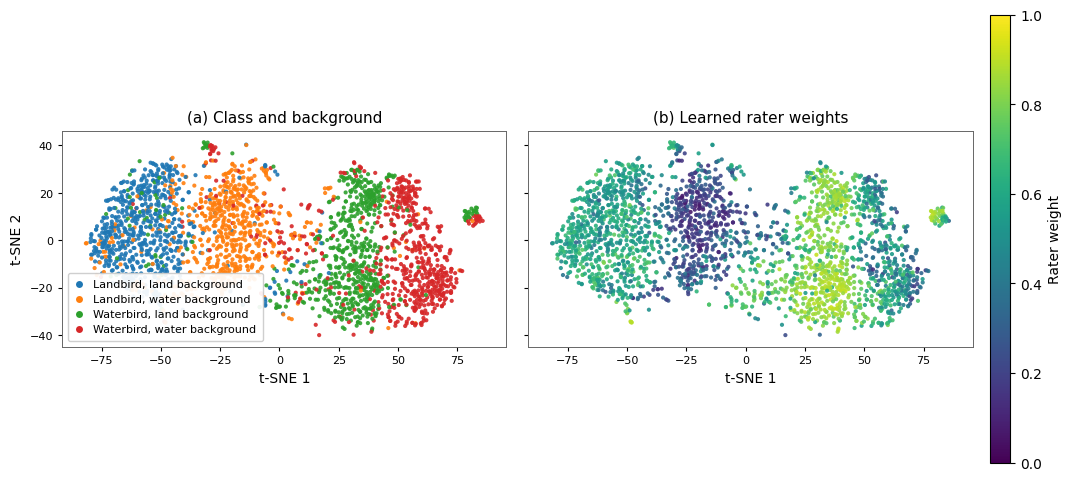

In [58]:
# 7. Publication figure: change aesthetics here without rerunning t-SNE.
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.titlesize": 11, "axes.labelsize": 10,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})

def draw_weight_tsne(frame):
    fig = plt.figure(figsize=(10.6, 4.7), layout="constrained")
    grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.045], wspace=0.05)
    left = fig.add_subplot(grid[0, 0])
    right = fig.add_subplot(grid[0, 1], sharex=left, sharey=left)
    colorbar_axis = fig.add_subplot(grid[0, 2])
    axes = (left, right)
    # Same shuffled draw order in both panels; weights never determine occlusion.
    order = np.random.default_rng(SAMPLE_SEED + 981).permutation(len(frame))
    draw = frame.iloc[order]
    group_ids = draw.pair_id.to_numpy().astype(int)
    palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
    if len(pair_labels) > len(palette):
        palette = [mpl.colors.to_hex(c) for c in mpl.colormaps["tab20"].colors]
    group_colors = [palette[gid % len(palette)] for gid in group_ids]
    scatter_kwargs = dict(s=POINT_SIZE, alpha=POINT_ALPHA, linewidths=0, rasterized=False)
    left.scatter(draw.tsne_x, draw.tsne_y, c=group_colors, **scatter_kwargs)

    values = draw.color_value.to_numpy()
    if COLOR_LIMITS is not None:
        low, high = map(float, COLOR_LIMITS)
    elif COLOR_VALUE == "rater_weight":
        low, high = 0.0, float(WEIGHT_SCALE)
    else:
        low, high = float(all_points.color_value.min()), float(all_points.color_value.max())
        if low == high:
            low, high = low - 0.5, high + 0.5
    if not np.isfinite([low, high]).all() or low >= high:
        raise ValueError("COLOR_LIMITS must be finite and strictly increasing.")
    norm = Normalize(vmin=low, vmax=high)
    right.scatter(draw.tsne_x, draw.tsne_y, c=values, cmap="viridis", norm=norm, **scatter_kwargs)
    # Opaque colorbar represents the specified weights rather than alpha blending.
    mappable = mpl.cm.ScalarMappable(norm=norm, cmap="viridis")
    below, above = np.any(values < low), np.any(values > high)
    extend = "both" if below and above else "min" if below else "max" if above else "neither"
    cbar = fig.colorbar(mappable, cax=colorbar_axis, extend=extend)
    cbar.set_label(COLOR_LABEL)
    handles = [mpl.lines.Line2D([], [], marker="o", linestyle="", markersize=5,
                markerfacecolor=palette[gid % len(palette)], markeredgewidth=0,
                label=pair_labels[gid]) for gid in sorted(frame.pair_id.unique())]
    left.legend(handles=handles, loc="best", fontsize=8, framealpha=0.93,
                borderpad=0.6, handlelength=0.9, labelspacing=0.45)
    left.set_title("(a) Class and background")
    right.set_title("(b) Learned rater weights" if COLOR_VALUE == "rater_weight" else "(b) Raw rater scores")
    for ax in axes:
        ax.set_xlabel("t-SNE 1")
        ax.set_aspect("equal", adjustable="box")
        ax.tick_params(length=3, labelsize=8)
        ax.margins(0.06)
        for spine in ax.spines.values():
            spine.set_linewidth(0.7)
            spine.set_color("0.4")
        if not SHOW_TICKS:
            ax.set_xticks([])
            ax.set_yticks([])
    left.set_ylabel("t-SNE 2")
    right.tick_params(labelleft=False)
    return fig

figure = draw_weight_tsne(plotted_points)
plt.show()


In [59]:
# 8. Save figure + full scores + plotted coordinates + provenance to Drive.
OUTPUT_DIR = Path(OUTPUT_ROOT) / f"{PLOT_SPLIT}_{COLOR_VALUE}_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
basename = f"feature_rater_tsne_{PLOT_SPLIT}"
saved_files = []
for extension in SAVE_FORMATS:
    if extension not in {"png", "pdf", "svg"}:
        raise ValueError(f"Unsupported export format: {extension}")
    destination = OUTPUT_DIR / f"{basename}.{extension}"
    figure.savefig(destination, dpi=PNG_DPI, bbox_inches="tight", facecolor="white")
    saved_files.append(destination)
all_points.to_csv(OUTPUT_DIR / "all_sample_scores.csv", index=False)
plotted_points.to_csv(OUTPUT_DIR / "plotted_points.csv", index=False)
summary.to_csv(OUTPUT_DIR / "group_summary_full_split.csv", index=False)
np.savez_compressed(OUTPUT_DIR / "tsne_coordinates.npz", coordinates=coordinates,
                    split_rows=selected_rows, source_indices=plotted_points.source_index.to_numpy())

def checkpoint_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def json_compatible(value):
    if isinstance(value, dict):
        return {str(k): json_compatible(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_compatible(v) for v in value]
    if torch.is_tensor(value):
        return json_compatible(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_compatible(value.tolist())
    if isinstance(value, np.generic):
        return json_compatible(value.item())
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if value is None or isinstance(value, (str, float, int, bool)):
        return value
    return str(value)

manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "source_notebook": "Frozen_Rater_Final_Classifier_MultiSeed_MultiSelection (1).ipynb",
    "rater_checkpoint": str(RATER_CHECKPOINT), "rater_sha256": checkpoint_sha256(RATER_CHECKPOINT),
    "rater_capacity": capacity, "expected_erm_fingerprint": EXPECTED_ERM_FINGERPRINT,
    "plot_split": PLOT_SPLIT, "normalization_reference_split": NORMALIZATION_REFERENCE_SPLIT,
    "split_val": SPLIT_VAL, "data_split_seed": DATA_SPLIT_SEED,
    "color_value": COLOR_VALUE, "color_limits": COLOR_LIMITS,
    "color_range_rule": ("explicit override" if COLOR_LIMITS is not None else
                         "actual sigmoid range" if COLOR_VALUE == "rater_weight" else "full-split raw-score range"),
    "normalization_mode": NORMALIZATION_MODE, "weight_transform": WEIGHT_TRANSFORM,
    "temperature": TEMPERATURE, "weight_scale": WEIGHT_SCALE, "rating_mode": RATING_MODE,
    "global_rater_mean": global_mean, "global_rater_std": global_std,
    "n_full_split": len(all_points), "n_plotted": len(plotted_points),
    "sampling": SAMPLING, "max_points": MAX_POINTS, "sample_seed": SAMPLE_SEED,
    "l2_normalize_for_tsne": L2_NORMALIZE_FOR_TSNE,
    "pca_components_requested": PCA_COMPONENTS,
    "pca_components_actual": None if pca_model is None else pca_model.n_components_,
    "pca_retained_variance": None if pca_model is None else pca_model.explained_variance_ratio_.sum(),
    "tsne_parameters": tsne_model.get_params(), "tsne_kl_divergence": tsne_model.kl_divergence_,
    "cache_provenance": cache_provenance, "final_run_config": FINAL_RUN_CONFIG,
    "class_names": CLASS_NAMES, "background_names": BACKGROUND_NAMES,
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "numpy": np.__version__, "sklearn": sklearn.__version__, "matplotlib": mpl.__version__},
    "device": DEVICE, "point_size": POINT_SIZE, "point_alpha": POINT_ALPHA,
    "interpretation": "Frozen ERM features; weights on held-out samples are assigned for analysis, not test-time training.",
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(json_compatible(manifest), indent=2, allow_nan=False))
split_description = "test set" if PLOT_SPLIT == "test" else f"{PLOT_SPLIT} split"
sampling_description = ("all samples" if SAMPLING == "all" else
                        "a uniform random sample" if SAMPLING == "random" else "a group-balanced sample")
color_description = ("weights assigned by the frozen rater under the final-classifier weighting rule"
                     if COLOR_VALUE == "rater_weight" else "raw frozen-rater scores")
caption = (
    f"t-SNE visualization of frozen ERM embeddings on the Waterbirds {split_description} "
    f"({sampling_description}; n={len(plotted_points)}). Left: class/background groups. "
    f"Right: {color_description}; yellow denotes higher values and dark purple lower values. "
    "Both panels use the same samples and coordinates."
)
(OUTPUT_DIR / "suggested_caption.txt").write_text(caption + "\n")
print("Saved to:", OUTPUT_DIR)
for file in sorted(p for p in OUTPUT_DIR.iterdir() if not p.name.startswith(".")):
    print(" •", file.name)
print("\nSuggested caption:\n", caption)


Saved to: /content/drive/MyDrive/evidential_alignment_colab/feature_rater_tsne/test_rater_weight_20261028_074250_867245
 • all_sample_scores.csv
 • feature_rater_tsne_test.pdf
 • feature_rater_tsne_test.png
 • feature_rater_tsne_test.svg
 • group_summary_full_split.csv
 • manifest.json
 • plotted_points.csv
 • suggested_caption.txt
 • tsne_coordinates.npz

Suggested caption:
 t-SNE visualization of frozen ERM embeddings on the Waterbirds test set (a group-balanced sample; n=2568). Left: class/background groups. Right: weights assigned by the frozen rater under the final-classifier weighting rule; yellow denotes higher values and dark purple lower values. Both panels use the same samples and coordinates.


### Reading and adjusting the result

- **Which split?** Use `test` to match the reference's held-out visualization; use
  `val_subset1` to show weights assigned on the final-classifier training data.
- **Which representation?** This plots the ERM embeddings supplied to the rater. Your
  final classifier is linear on these fixed features, so training it does not create a
  new learned feature space. This figure demonstrates the weighting pattern.
- **No visible separation?** That is an empirical outcome. Do not include weights or group
  labels in t-SNE inputs to force separation. Check the numerical group summary as well.
- **Weights all look alike?** Look at the full-split range and raw-score distribution. Set
  `COLOR_VALUE="raw_score"` to inspect the scorer. The sigmoid colorbar is intentionally
  not stretched to imply stronger differences; narrower color limits should be disclosed.
- **Small minority groups?** Prefer the full test set first. A balanced view is available,
  but its altered sampling must be stated (the saved caption does so).
- **Path changed?** Update `RATER_CHECKPOINT` and `EMBEDDING_CACHE_ROOT` in cell 2. A fingerprint
  or architecture mismatch is an error rather than an invitation to silently load another model.

You can change the style and rerun cells 7–8 without refitting t-SNE. Change the split,
scoring settings, or checkpoint: rerun from cell 2. Exported CSVs and the manifest allow you
to inspect every plotted value and report the exact visualization settings.

**Validation note:** the notebook code was exercised with synthetic caches/checkpoints for
both supported rater architectures, including in-memory validation splitting and exports.
The actual learned pattern must be checked by running against your Drive files; those
checkpoint/cache files were not included in the upload.
